<a href="https://colab.research.google.com/github/Milla-Akbarany/Datathon/blob/main/Datathon_T017_DeepLearning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Datathon Deep Learning – Tim T017
Notebook ini disusun mengikuti **alur kerja 6 fase** dari ketentuan dosen. Setiap fase diawali dengan markdown berisi *checklist ketentuan* supaya mudah dicek sudah terpenuhi atau belum.

| Fase | Isi | Output utama |
|---|---|---|
| 0 | Setup & koneksi Google Drive | struktur folder proyek |
| 1 | EDA Dataset A, B, C | `eda_summary.csv`, grafik distribusi kelas |
| 2 | Preprocessing & split validasi | `models/preprocessor_*.pkl` |
| 3 | Eksperimen model Neural Network (3 konfigurasi/dataset) | `experiments.csv`, kurva loss, confusion matrix, model terbaik |
| 3b | Pembanding non-DL (RF/XGBoost) – hanya untuk laporan | tabel pembanding |
| 4 | Generate & validasi file submission | `predictions/T017_<DATASET>_<ATTEMPT>.csv` |
| 5 | Bahan laporan & ZIP | `requirements.txt`, ZIP proyek |
| 6 | Checklist pengumpulan final | – |

## Fase 0 – Setup & Koneksi Google Drive

**Checklist ketentuan**
- [ ] ID Tim sudah benar (`T017`)
- [ ] Dataset A, B, C (`train`, `test`, `sample_submission`) sudah ada di Google Drive
- [ ] Struktur folder proyek: `code/`, `models/`, `predictions/`, `requirements.txt`, `experiments.csv`

**Cara menyiapkan data di Drive**
1. Buka link folder dataset → klik kanan folder → **Organize → Add shortcut** (atau **Make a copy**) ke *My Drive*.
2. Jalankan sel di bawah, izinkan akses Drive.
3. Kalau folder tidak terdeteksi otomatis, isi `DATA_DIR` secara manual.

In [2]:
import os, glob, time, random, json, shutil, joblib, warnings
import numpy as np, pandas as pd, tensorflow as tf
import matplotlib.pyplot as plt
from google.colab import drive

warnings.filterwarnings('ignore')
drive.mount('/content/drive')

TEAM = 'T017'
SEED = 42

# --- Lokasi dataset ---
DATA_DIR  = ''   # biarkan kosong = cari otomatis (atau isi path folder, BUKAN link)
DRIVE_URL = 'https://drive.google.com/drive/folders/11BDxwZ7-Iza02X5PL2tf649I3bPmQoUq?usp=sharing'

def find_in_drive():
    for pat in ['/content/drive/MyDrive/**/train_B.csv', '/content/drive/Shareddrives/**/train_B.csv']:
        hits = glob.glob(pat, recursive=True)
        if hits:
            return os.path.dirname(hits[0])
    return ''

if not DATA_DIR:
    DATA_DIR = find_in_drive()

if not DATA_DIR:
    print('Tidak ditemukan di Drive -> mencoba unduh langsung dari link (gdown)...')
    import gdown
    gdown.download_folder(DRIVE_URL, output='/content/dataset', quiet=False, use_cookies=False)
    hits = glob.glob('/content/dataset/**/train_B.csv', recursive=True)
    if hits:
        DATA_DIR = os.path.dirname(hits[0])

if not DATA_DIR:
    raise FileNotFoundError('Dataset tidak ditemukan. Tambahkan shortcut folder ke My Drive (Cara 1) lalu jalankan ulang.')

print('DATA_DIR  :', DATA_DIR)
print('Isi folder:', sorted(os.listdir(DATA_DIR)))

# --- Folder proyek (disimpan di Drive agar tidak hilang saat runtime reset) ---
PROJECT = '/content/drive/MyDrive/datathon_T017'
for d in ['code', 'models', 'predictions', 'figures']:
    os.makedirs(f'{PROJECT}/{d}', exist_ok=True)
print('PROJECT   :', PROJECT)

DATASETS = {
    'A': ('train.csv',   'test.csv'),
    'B': ('train_B.csv', 'test_B.csv'),
    'C': ('train_C.csv', 'test_C.csv'),
}

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
DATA_DIR  : /content/drive/MyDrive/student/dataset_B
Isi folder: ['sample_submission_B.csv', 'test_B.csv', 'train_B.csv']
PROJECT   : /content/drive/MyDrive/datathon_T017


In [3]:
BASE = os.path.dirname(DATA_DIR)          # /content/drive/MyDrive/student
print('Isi folder induk:', sorted(os.listdir(BASE)))

def pick(folder, pattern):
    m = sorted(glob.glob(f'{folder}/{pattern}'))
    return m[0] if m else None

PATHS = {}
for key in ['A', 'B', 'C']:
    folder = f'{BASE}/dataset_{key}'
    if not os.path.isdir(folder):
        raise FileNotFoundError(f'Folder {folder} tidak ada. Lihat daftar "Isi folder induk" di atas dan sesuaikan nama foldernya.')
    PATHS[key] = dict(train=pick(folder, 'train*.csv'),
                      test=pick(folder, 'test*.csv'),
                      sample=pick(folder, 'sample_submission*.csv'))
    print(f'\nDataset {key}: {folder}')
    for k, v in PATHS[key].items():
        print(f'  {k:<7}:', os.path.basename(v) if v else 'TIDAK DITEMUKAN')
    assert PATHS[key]['train'] and PATHS[key]['test'], f'train/test Dataset {key} tidak ditemukan'

Isi folder induk: ['PERATURAN.md', 'dataset_A', 'dataset_B', 'dataset_C']

Dataset A: /content/drive/MyDrive/student/dataset_A
  train  : train.csv
  test   : test.csv
  sample : sample_submission.csv

Dataset B: /content/drive/MyDrive/student/dataset_B
  train  : train_B.csv
  test   : test_B.csv
  sample : sample_submission_B.csv

Dataset C: /content/drive/MyDrive/student/dataset_C
  train  : train_C.csv
  test   : test_C.csv
  sample : sample_submission_C.csv


## Fase 1 – Exploratory Data Analysis (EDA)

**Checklist ketentuan**
- [ ] Jumlah sampel (baris) dan fitur (kolom) tiap dataset
- [ ] Cek missing values / nilai aneh
- [ ] Distribusi kelas target (seimbang atau imbalanced)
- [ ] Semua temuan dicatat → masuk **Bab 2 Laporan Final** (tabel ringkasan disimpan ke `eda_summary.csv`)


===== DATASET A =====
Train: (36249, 10) | Test: (9063, 9)
Jumlah fitur       : 8 (0 kategorikal)
Missing train/test : 0 / 0
Duplikat baris     : 0
Kolom konstan      : []
Kolom test = train : True
Distribusi kelas (%):
target
0    42.45
1    57.55


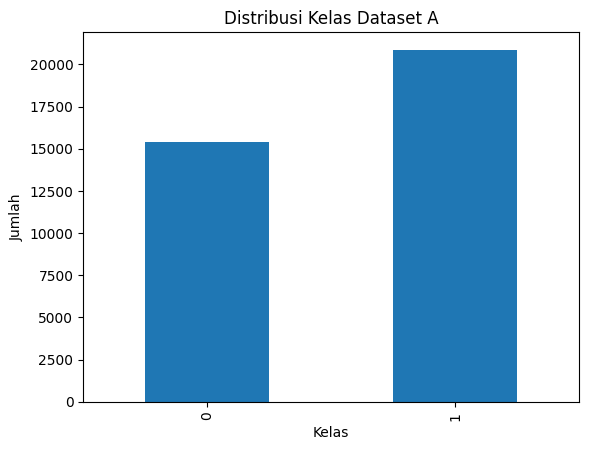


===== DATASET B =====
Train: (63988, 35) | Test: (15998, 34)
Jumlah fitur       : 33 (0 kategorikal)
Missing train/test : 0 / 0
Duplikat baris     : 0
Kolom konstan      : []
Kolom test = train : True
Distribusi kelas (%):
target
0    16.67
1    16.67
2    16.67
3    16.67
4    16.67
5    16.67


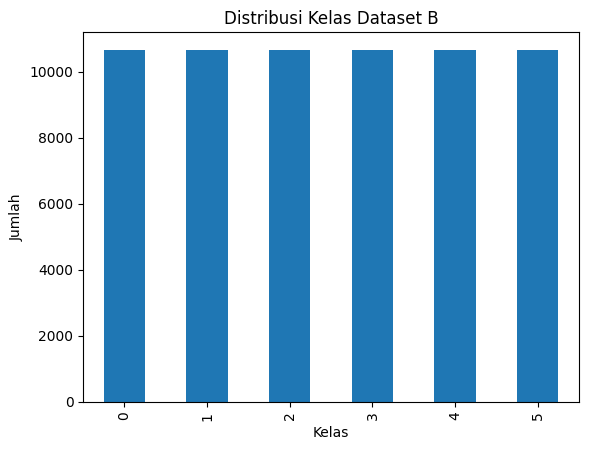


===== DATASET C =====
Train: (9600, 5) | Test: (2400, 4)
Jumlah fitur       : 3 (0 kategorikal)
Missing train/test : 0 / 0
Duplikat baris     : 0
Kolom konstan      : []
Kolom test = train : True
Distribusi kelas (%):
target
0    64.47
1    35.53


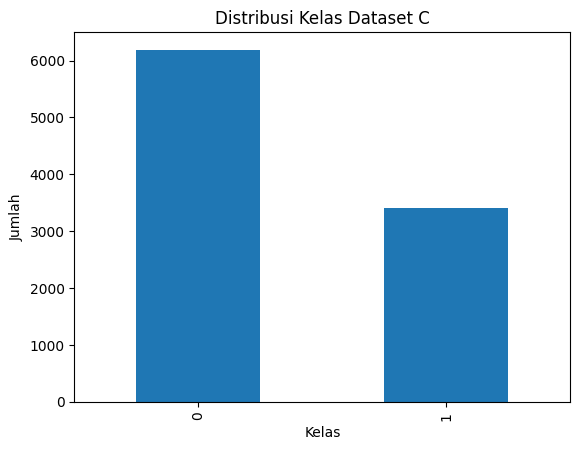

,dataset,n_train,n_test,n_features,n_categorical,missing_train,missing_test,n_classes,majority_class_pct,minority_class_pct,imbalance_ratio
0,A,36249,9063,8,0,0,0,2,57.55,42.45,1.36
1,B,63988,15998,33,0,0,0,6,16.67,16.67,1.00
2,C,9600,2400,3,0,0,0,2,64.47,35.53,1.81


In [4]:
eda_rows, RAW = [], {}
for key, p in PATHS.items():
    train = pd.read_csv(p['train'])
    test  = pd.read_csv(p['test'])
    RAW[key] = (train, test)

    feats = [c for c in train.columns if c not in ('sample_id', 'target')]
    cls = train['target'].value_counts(normalize=True).sort_index()
    n_cat = len(train[feats].select_dtypes(exclude='number').columns)
    const = [c for c in feats if train[c].nunique() <= 1]

    print(f'\n===== DATASET {key} =====')
    print('Train:', train.shape, '| Test:', test.shape)
    print('Jumlah fitur       :', len(feats), f'({n_cat} kategorikal)')
    print('Missing train/test :', int(train.isna().sum().sum()), '/', int(test.isna().sum().sum()))
    print('Duplikat baris     :', int(train[feats].duplicated().sum()))
    print('Kolom konstan      :', const)
    print('Kolom test = train :', set(test.columns) == set(feats) | {'sample_id'})
    print('Distribusi kelas (%):'); print((cls * 100).round(2).to_string())

    eda_rows.append(dict(dataset=key, n_train=len(train), n_test=len(test), n_features=len(feats),
                         n_categorical=n_cat, missing_train=int(train.isna().sum().sum()),
                         missing_test=int(test.isna().sum().sum()), n_classes=train['target'].nunique(),
                         majority_class_pct=round(cls.max() * 100, 2), minority_class_pct=round(cls.min() * 100, 2),
                         imbalance_ratio=round(cls.max() / cls.min(), 2)))

    ax = (train['target'].value_counts().sort_index()).plot(kind='bar', title=f'Distribusi Kelas Dataset {key}')
    ax.set_xlabel('Kelas'); ax.set_ylabel('Jumlah')
    plt.savefig(f'{PROJECT}/figures/eda_class_{key}.png', dpi=150, bbox_inches='tight'); plt.show()

eda_df = pd.DataFrame(eda_rows)
eda_df.to_csv(f'{PROJECT}/eda_summary.csv', index=False)
eda_df

## Fase 2 – Preprocessing & Pembagian Data

**Checklist ketentuan**
- [ ] Random seed ditetapkan (Python, NumPy, TensorFlow) → `seed = 42`
- [ ] `train.csv` dibagi Train/Validation **80:20 stratified**
- [ ] Kolom `sample_id` **dibuang** dari fitur (cegah data leakage)
- [ ] Scaling (StandardScaler) / encoding **di-fit hanya pada data train**
- [ ] Objek preprocessing disimpan dengan `joblib` ke `models/`

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); tf.keras.utils.set_random_seed(s)
set_seed()

DATA = {}
for key, (train, test) in RAW.items():
    X = train.drop(columns=['sample_id', 'target'])      # sample_id TIDAK jadi fitur
    X_test = test.drop(columns=['sample_id'])
    le = LabelEncoder().fit(train['target'])               # label -> 0..K-1
    y = le.transform(train['target'])

    X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.20, random_state=SEED, stratify=y)

    num_cols = X.select_dtypes(include='number').columns.tolist()
    cat_cols = X.select_dtypes(exclude='number').columns.tolist()
    parts = [('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num_cols)]
    if cat_cols:
        parts.append(('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                                       ('oh', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat_cols))
    pre = ColumnTransformer(parts)

    Xtr_s  = pre.fit_transform(X_tr).astype('float32')     # fit HANYA di train
    Xval_s = pre.transform(X_val).astype('float32')
    Xte_s  = pre.transform(X_test).astype('float32')

    joblib.dump(pre, f'{PROJECT}/models/preprocessor_{key.lower()}.pkl')
    joblib.dump(le,  f'{PROJECT}/models/labelencoder_{key.lower()}.pkl')

    DATA[key] = dict(Xtr=Xtr_s, Xval=Xval_s, Xte=Xte_s, ytr=y_tr, yval=y_val, le=le,
                     test_ids=test['sample_id'].values, n_classes=len(le.classes_))
    print(f'Dataset {key}: train {Xtr_s.shape} | val {Xval_s.shape} | test {Xte_s.shape} | kelas {list(le.classes_)}')

Dataset A: train (28999, 8) | val (7250, 8) | test (9063, 8) | kelas [np.int64(0), np.int64(1)]
Dataset B: train (51190, 33) | val (12798, 33) | test (15998, 33) | kelas [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
Dataset C: train (7680, 3) | val (1920, 3) | test (2400, 3) | kelas [np.int64(0), np.int64(1)]


## Fase 3 – Eksperimen Model Neural Network

**Checklist ketentuan**
- [ ] Prediksi dihasilkan oleh **Neural Network (MLP)**
- [ ] Minimal 2 konfigurasi per dataset (di sini **3**): Baseline, Deeper, Optimized
- [ ] Konfigurasi *Optimized* memvariasikan: jumlah layer/neuron, **aktivasi (ReLU → GELU)**, Dropout, Learning Rate, Batch Size, **optimizer (Adam → AdamW)**
- [ ] **Early Stopping** dipakai di semua konfigurasi (+ ReduceLROnPlateau)
- [ ] Rekap ke `experiments.csv`: `dataset, config_name, seed, val_accuracy, val_error, training_time`
- [ ] Kurva **training vs validation loss** disimpan
- [ ] **Confusion matrix** validasi model terbaik disimpan


=========== DATASET A (kelas=2, imbalanced=False) ===========
Config_1_Baseline    val_acc=0.8112 | val_err=0.1888 | epoch=100 | 268.0s
Config_2_Deeper      val_acc=0.8274 | val_err=0.1726 | epoch=100 | 150.8s
Config_3_Optimized   val_acc=0.8073 | val_err=0.1927 | epoch=81 | 157.5s
--> TERBAIK Dataset A: Config_2_Deeper (0.8274)


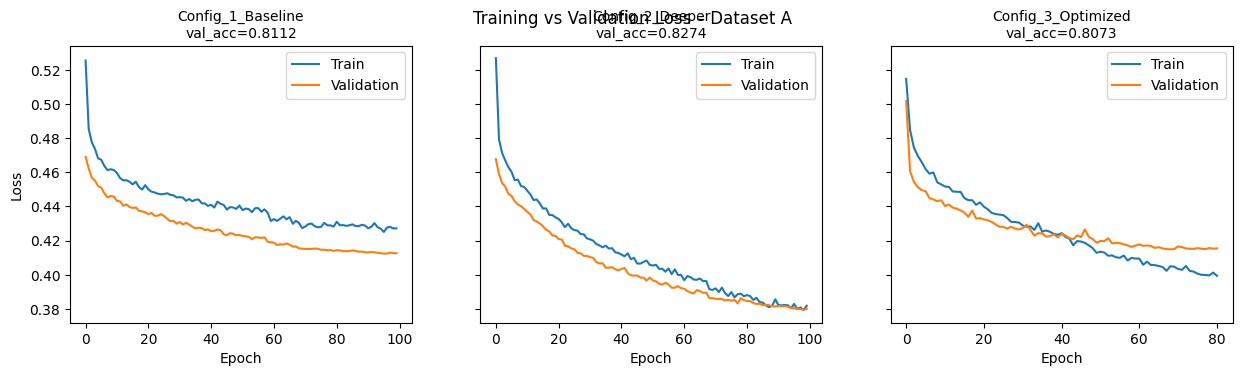

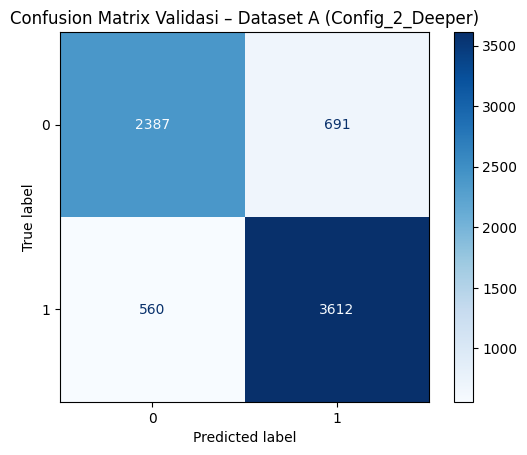


=========== DATASET B (kelas=6, imbalanced=False) ===========
Config_1_Baseline    val_acc=0.5813 | val_err=0.4187 | epoch=100 | 421.1s
Config_2_Deeper      val_acc=0.5938 | val_err=0.4062 | epoch=100 | 258.1s
Config_3_Optimized   val_acc=0.5923 | val_err=0.4077 | epoch=88 | 283.1s
--> TERBAIK Dataset B: Config_2_Deeper (0.5938)


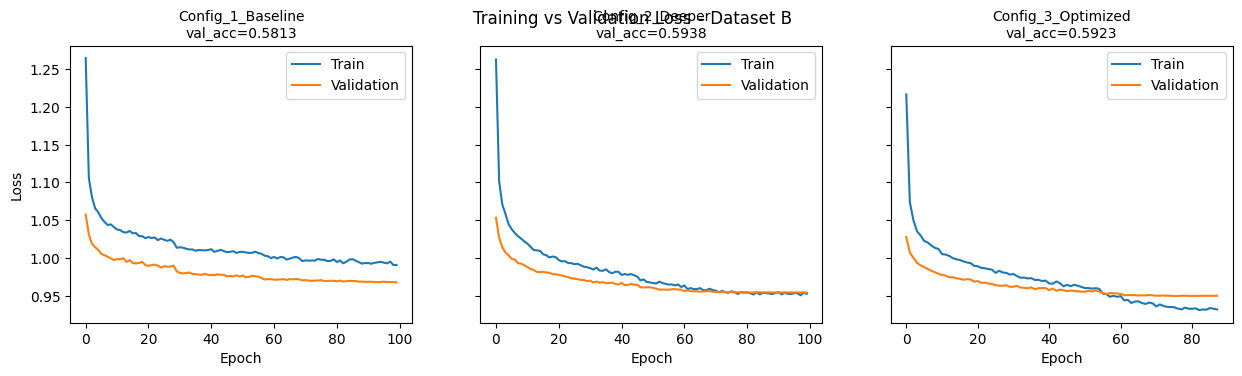

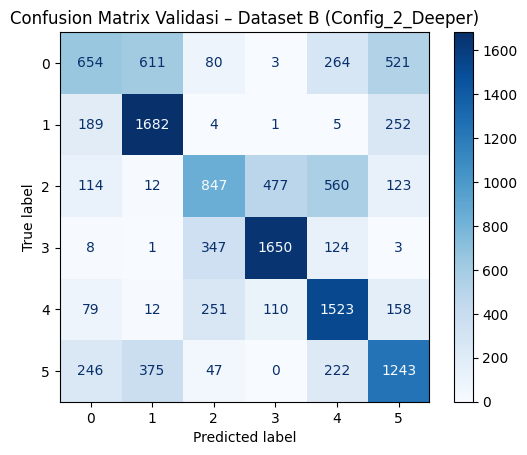


=========== DATASET C (kelas=2, imbalanced=True) ===========
Config_1_Baseline    val_acc=0.8583 | val_err=0.1417 | epoch=39 | 25.7s
Config_2_Deeper      val_acc=0.8594 | val_err=0.1406 | epoch=37 | 19.4s
Config_3_Optimized   val_acc=0.8562 | val_err=0.1438 | epoch=19 | 12.4s
--> TERBAIK Dataset C: Config_2_Deeper (0.8594)


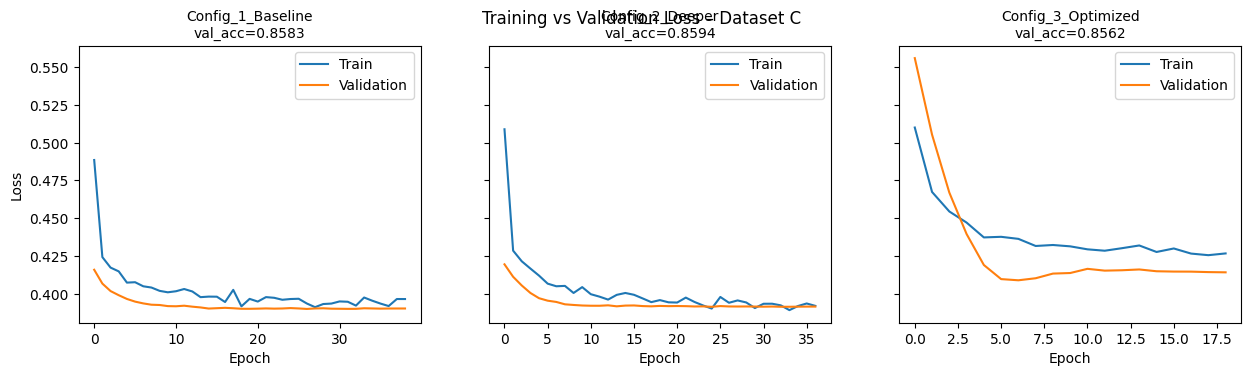

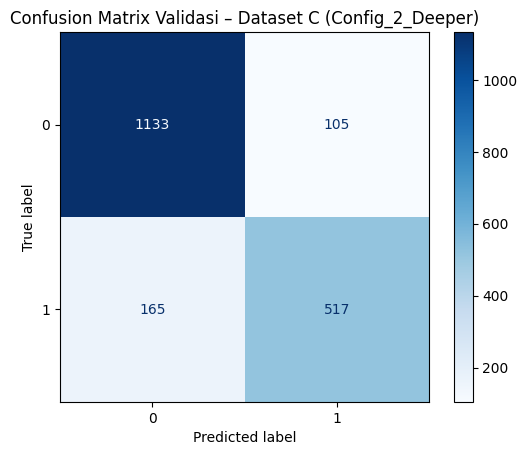

,dataset,config_name,seed,val_accuracy,val_error,training_time
0,A,Config_1_Baseline,42,0.81117,0.18883,268.02
1,A,Config_2_Deeper,42,0.82745,0.17255,150.78
2,A,Config_3_Optimized,42,0.80731,0.19269,157.55
3,B,Config_1_Baseline,42,0.58126,0.41874,421.10
4,B,Config_2_Deeper,42,0.59376,0.40624,258.10
5,B,Config_3_Optimized,42,0.59228,0.40772,283.12
6,C,Config_1_Baseline,42,0.85833,0.14167,25.67
7,C,Config_2_Deeper,42,0.85938,0.14062,19.42
8,C,Config_3_Optimized,42,0.85625,0.14375,12.44


In [6]:
from tensorflow.keras import layers, models, callbacks
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.utils.class_weight import compute_class_weight

CONFIGS = [
    dict(name='Config_1_Baseline',  layers=[64, 32],       act='relu', dropout=0.3, lr=1e-3, batch=32,  opt='adam',  bn=False, cw=False),
    dict(name='Config_2_Deeper',    layers=[128, 64, 32],  act='relu', dropout=0.2, lr=5e-4, batch=64,  opt='adam',  bn=False, cw=False),
    dict(name='Config_3_Optimized', layers=[256, 128, 64], act='gelu', dropout=0.3, lr=1e-3, batch=128, opt='adamw', bn=True,  cw=True),
]
MAX_EPOCHS = 100

def build_model(n_feat, n_cls, c):
    m = models.Sequential([layers.Input(shape=(n_feat,))])
    for u in c['layers']:
        m.add(layers.Dense(u))
        if c['bn']: m.add(layers.BatchNormalization())
        m.add(layers.Activation(c['act']))
        m.add(layers.Dropout(c['dropout']))
    if n_cls > 2:
        m.add(layers.Dense(n_cls, activation='softmax')); loss = 'sparse_categorical_crossentropy'
    else:
        m.add(layers.Dense(1, activation='sigmoid'));      loss = 'binary_crossentropy'
    opt = (tf.keras.optimizers.AdamW(learning_rate=c['lr'], weight_decay=1e-4) if c['opt'] == 'adamw'
           else tf.keras.optimizers.Adam(learning_rate=c['lr']))
    m.compile(optimizer=opt, loss=loss, metrics=['accuracy'])
    return m

def to_labels(prob, n_cls):
    return np.argmax(prob, axis=1) if n_cls > 2 else (prob.ravel() > 0.5).astype(int)

rows, RESULTS = [], {}
for key, d in DATA.items():
    n_cls = d['n_classes']
    ratio = pd.Series(d['ytr']).value_counts(normalize=True)
    imbalanced = ratio.max() / ratio.min() > 1.5
    cw_all = dict(enumerate(compute_class_weight('balanced', classes=np.unique(d['ytr']), y=d['ytr'])))
    RESULTS[key] = dict(runs=[])
    print(f'\n=========== DATASET {key} (kelas={n_cls}, imbalanced={imbalanced}) ===========')

    for c in CONFIGS:
        set_seed()
        model = build_model(d['Xtr'].shape[1], n_cls, c)
        cbs = [callbacks.EarlyStopping(monitor='val_loss', patience=12, restore_best_weights=True),
               callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-5)]
        use_cw = c['cw'] and imbalanced
        t0 = time.time()
        h = model.fit(d['Xtr'], d['ytr'], validation_data=(d['Xval'], d['yval']),
                      epochs=MAX_EPOCHS, batch_size=c['batch'], callbacks=cbs, verbose=0,
                      class_weight=cw_all if use_cw else None)
        t_train = time.time() - t0

        vpred = to_labels(model.predict(d['Xval'], verbose=0), n_cls)
        acc = accuracy_score(d['yval'], vpred)
        print(f"{c['name']:<20} val_acc={acc:.4f} | val_err={1-acc:.4f} | epoch={len(h.history['loss'])} | {t_train:.1f}s")

        rows.append(dict(dataset=key, config_name=c['name'], seed=SEED,
                         val_accuracy=round(acc, 5), val_error=round(1 - acc, 5), training_time=round(t_train, 2),
                         hidden_layers=str(c['layers']), activation=c['act'], dropout=c['dropout'],
                         learning_rate=c['lr'], batch_size=c['batch'], optimizer=c['opt'],
                         batch_norm=c['bn'], class_weight=use_cw, epochs_run=len(h.history['loss'])))
        RESULTS[key]['runs'].append(dict(cfg=c, model=model, hist=h.history, vpred=vpred, acc=acc))

    # model terbaik
    best = max(RESULTS[key]['runs'], key=lambda r: r['acc'])
    RESULTS[key]['best'] = best
    best['model'].save(f"{PROJECT}/models/model_{key.lower()}_best.keras")
    print(f"--> TERBAIK Dataset {key}: {best['cfg']['name']} ({best['acc']:.4f})")

    # kurva loss semua konfigurasi
    fig, axs = plt.subplots(1, len(CONFIGS), figsize=(5 * len(CONFIGS), 3.6), sharey=True)
    for ax, r in zip(axs, RESULTS[key]['runs']):
        ax.plot(r['hist']['loss'], label='Train'); ax.plot(r['hist']['val_loss'], label='Validation')
        ax.set_title(f"{r['cfg']['name']}\nval_acc={r['acc']:.4f}", fontsize=10); ax.set_xlabel('Epoch'); ax.legend()
    axs[0].set_ylabel('Loss'); fig.suptitle(f'Training vs Validation Loss – Dataset {key}')
    plt.savefig(f'{PROJECT}/figures/loss_{key}.png', dpi=150, bbox_inches='tight'); plt.show()

    # confusion matrix model terbaik
    ConfusionMatrixDisplay(confusion_matrix(d['yval'], best['vpred'])).plot(cmap='Blues')
    plt.title(f"Confusion Matrix Validasi – Dataset {key} ({best['cfg']['name']})")
    plt.savefig(f'{PROJECT}/figures/cm_{key}.png', dpi=150, bbox_inches='tight'); plt.show()

exp_df = pd.DataFrame(rows)
exp_df.to_csv(f'{PROJECT}/experiments.csv', index=False)
exp_df[['dataset', 'config_name', 'seed', 'val_accuracy', 'val_error', 'training_time']]

## Fase 3b – Pembanding Non-Deep-Learning (hanya untuk laporan)

**Checklist ketentuan**
- [ ] Random Forest / XGBoost **hanya sebagai pembanding** di laporan, **bukan** untuk submission
- [ ] Bandingkan dengan MLP terbaik: kalau selisihnya besar, arsitektur MLP masih bisa diperbaiki

In [7]:
from sklearn.ensemble import RandomForestClassifier
try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except Exception:
    HAS_XGB = False

cmp_rows = []
for key, d in DATA.items():
    t0 = time.time()
    rf = RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED).fit(d['Xtr'], d['ytr'])
    cmp_rows.append(dict(dataset=key, model='RandomForest (pembanding)', val_accuracy=accuracy_score(d['yval'], rf.predict(d['Xval'])),
                         time_s=round(time.time() - t0, 1)))
    if HAS_XGB:
        t0 = time.time()
        xgb = XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1, random_state=SEED, n_jobs=-1).fit(d['Xtr'], d['ytr'])
        cmp_rows.append(dict(dataset=key, model='XGBoost (pembanding)', val_accuracy=accuracy_score(d['yval'], xgb.predict(d['Xval'])),
                             time_s=round(time.time() - t0, 1)))
    b = RESULTS[key]['best']
    cmp_rows.append(dict(dataset=key, model=f"MLP terbaik – {b['cfg']['name']}", val_accuracy=b['acc'], time_s=np.nan))

cmp_df = pd.DataFrame(cmp_rows).sort_values(['dataset', 'val_accuracy'], ascending=[True, False])
cmp_df['val_accuracy'] = cmp_df['val_accuracy'].round(4)
cmp_df.to_csv(f'{PROJECT}/baseline_comparison.csv', index=False)
cmp_df

,dataset,model,val_accuracy,time_s
0,A,RandomForest (pembanding),0.8403,31.8
2,A,MLP terbaik – Config_2_Deeper,0.8274,NaN
1,A,XGBoost (pembanding),0.8243,3.7
5,B,MLP terbaik – Config_2_Deeper,0.5938,NaN
3,B,RandomForest (pembanding),0.5592,161.0
4,B,XGBoost (pembanding),0.5577,36.9
8,C,MLP terbaik – Config_2_Deeper,0.8594,NaN
6,C,RandomForest (pembanding),0.8448,3.9
7,C,XGBoost (pembanding),0.8432,2.6


## Fase 4 – Generate & Validasi File Submission

**Checklist ketentuan**
- [ ] Prediksi dari **model Neural Network terbaik**, preprocessing memakai objek dari Fase 2
- [ ] Output berupa **label kelas** (bukan probabilitas)
- [ ] Tepat **2 kolom**: `sample_id,target`
- [ ] Setiap ID test muncul **tepat 1 kali**, jumlah baris = jumlah baris `test.csv`
- [ ] Ukuran file **< 5 MB**
- [ ] Nama file: `T<ID_TIM>_<DATASET>_<ATTEMPT>.csv` (contoh `T017_A_01.csv`)
- [ ] Maksimal **3 submission valid per dataset** (total 9) – dikirim oleh **Ketua Tim** lewat Form Submission
- [ ] Catat attempt dengan Public Accuracy tertinggi dari leaderboard

> Ubah `ATTEMPT_PLAN` untuk setiap kali membuat submission baru. File lama **tidak akan ditimpa** kecuali `OVERWRITE = True`.

In [11]:
# Pilih attempt & konfigurasi per dataset. None = pakai model terbaik otomatis.
ATTEMPT_PLAN = {'A': '01', 'B': '01', 'C': '01'}
CONFIG_PICK  = {'A': 'Config_2_Deeper', 'B': 'Config_2_Deeper', 'C': 'Config_2_Deeper'}   # contoh: 'Config_3_Optimized'
OVERWRITE = False
def find_sample_submission(key):
    return PATHS[key]['sample']

report = []
for key, d in DATA.items():
    runs = {r['cfg']['name']: r for r in RESULTS[key]['runs']}
    run = runs[CONFIG_PICK[key]] if CONFIG_PICK[key] else RESULTS[key]['best']

    pred_idx = to_labels(run['model'].predict(d['Xte'], verbose=0), d['n_classes'])
    pred = d['le'].inverse_transform(pred_idx)                    # kembalikan ke label asli
    sub = pd.DataFrame({'sample_id': d['test_ids'], 'target': pred})

    fname = f"{PROJECT}/predictions/{TEAM}_{key}_{ATTEMPT_PLAN[key]}.csv"
    if os.path.exists(fname) and not OVERWRITE:
        print(f'[SKIP] {os.path.basename(fname)} sudah ada (set OVERWRITE=True untuk menimpa)'); continue
    sub.to_csv(fname, index=False)

    # --- validasi aturan ---
    size_mb = os.path.getsize(fname) / 1e6
    chk = pd.read_csv(fname)
    checks = {
        '2 kolom (sample_id,target)': list(chk.columns) == ['sample_id', 'target'],
        'ID unik (1x)': chk['sample_id'].is_unique,
        'jumlah baris = test.csv': len(chk) == len(RAW[key][1]),
        'tanpa NaN': not chk.isna().any().any(),
        'ukuran < 5 MB': size_mb < 5,
        'nama file sesuai format': os.path.basename(fname) == f'{TEAM}_{key}_{ATTEMPT_PLAN[key]}.csv',
    }
    ss = find_sample_submission(key)
    if ss:
        ssdf = pd.read_csv(ss)
        checks['ID sama dgn sample_submission'] = set(ssdf['sample_id']) == set(chk['sample_id'])
    config_name = run['cfg']['name']
    print(f"\n{os.path.basename(fname)} | {config_name} | val_acc={run['acc']:.4f} | {size_mb:.2f} MB")
    print('  distribusi prediksi:', chk['target'].value_counts().sort_index().to_dict())
    for k, v in checks.items(): print(f"  [{'OK' if v else 'GAGAL'}] {k}")
    report.append(dict(file=os.path.basename(fname), config=config_name, val_acc=round(run['acc'], 5), all_ok=all(checks.values())))
pd.DataFrame(report)

[SKIP] T017_A_01.csv sudah ada (set OVERWRITE=True untuk menimpa)
[SKIP] T017_B_01.csv sudah ada (set OVERWRITE=True untuk menimpa)
[SKIP] T017_C_01.csv sudah ada (set OVERWRITE=True untuk menimpa)


""


## Fase 5 – Bahan Laporan PDF & ZIP

**Checklist ketentuan**
- [ ] `requirements.txt` dibuat
- [ ] `experiments.csv` lengkap
- [ ] Simpan notebook ini ke `code/` (**File → Download → .ipynb**, lalu unggah ke `datathon_T017/code/`)
- [ ] Gambar untuk laporan tersedia di `figures/` (EDA, kurva loss, confusion matrix)
- [ ] Ringkasan hasil di bawah dipakai untuk Bab hasil/pembahasan

In [12]:
from importlib.metadata import version, PackageNotFoundError
pkgs = ['tensorflow', 'scikit-learn', 'pandas', 'numpy', 'joblib', 'matplotlib', 'xgboost']
lines = []
for p in pkgs:
    try: lines.append(f'{p}=={version(p)}')
    except PackageNotFoundError: pass
open(f'{PROJECT}/requirements.txt', 'w').write('\n'.join(lines) + '\n')
print(open(f'{PROJECT}/requirements.txt').read())

print('Ringkasan model terbaik per dataset:')
summary = pd.DataFrame([dict(dataset=k, best_config=v['best']['cfg']['name'], val_accuracy=round(v['best']['acc'], 4),
                             val_error=round(1 - v['best']['acc'], 4)) for k, v in RESULTS.items()])
display(summary)
print('\nIsi proyek:')
for root, _, files in os.walk(PROJECT):
    for f in sorted(files): print(' ', os.path.relpath(os.path.join(root, f), PROJECT))

tensorflow==2.21.0
scikit-learn==1.6.1
pandas==2.2.3
numpy==2.1.3
joblib==1.6.0
matplotlib==3.10.0
xgboost==3.4.1

Ringkasan model terbaik per dataset:


,dataset,best_config,val_accuracy,val_error
0,A,Config_2_Deeper,0.8274,0.1726
1,B,Config_2_Deeper,0.5938,0.4062
2,C,Config_2_Deeper,0.8594,0.1406



Isi proyek:
  T017_final.zip
  baseline_comparison.csv
  eda_summary.csv
  experiments.csv
  requirements.txt
  models/labelencoder_a.pkl
  models/labelencoder_b.pkl
  models/labelencoder_c.pkl
  models/model_a_best.keras
  models/model_b_best.keras
  models/model_c_best.keras
  models/preprocessor_a.pkl
  models/preprocessor_b.pkl
  models/preprocessor_c.pkl
  predictions/T017_A_01.csv
  predictions/T017_B_01.csv
  predictions/T017_C_01.csv
  figures/cm_A.png
  figures/cm_B.png
  figures/cm_C.png
  figures/eda_class_A.png
  figures/eda_class_B.png
  figures/eda_class_C.png
  figures/loss_A.png
  figures/loss_B.png
  figures/loss_C.png


## Fase 6 – Pengumpulan Final

**Checklist akhir**
- [ ] Public Accuracy terbaik tiap dataset sudah dicek di leaderboard → catat nomor attempt-nya
- [ ] Total submission ≤ 3 per dataset (maks. 9)
- [ ] Laporan PDF memuat: EDA (Bab 2), konfigurasi eksperimen, `experiments.csv`, kurva loss, confusion matrix, pembanding non-DL
- [ ] Notebook `.ipynb` sudah ada di `code/`
- [ ] ZIP berisi `code/`, `models/`, `predictions/`, `requirements.txt`, `experiments.csv`

In [13]:
# Buat ZIP proyek (jalankan setelah notebook .ipynb dimasukkan ke folder code/)
zip_base = f'/content/{TEAM}_final'
to_zip = '/content/zip_tmp'
shutil.rmtree(to_zip, ignore_errors=True); os.makedirs(to_zip)
for item in ['code', 'models', 'predictions', 'requirements.txt', 'experiments.csv']:
    src = f'{PROJECT}/{item}'
    if os.path.isdir(src): shutil.copytree(src, f'{to_zip}/{item}')
    elif os.path.exists(src): shutil.copy(src, to_zip)
path = shutil.make_archive(zip_base, 'zip', to_zip)
shutil.copy(path, PROJECT)
print('ZIP dibuat:', path, f'({os.path.getsize(path)/1e6:.1f} MB) – salinan juga di', PROJECT)

ZIP dibuat: /content/T017_final.zip (0.7 MB) – salinan juga di /content/drive/MyDrive/datathon_T017
